In [16]:
#Practica 6_ Realizado por Angel Antolin

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_digits
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

from tqdm import tqdm

# --------------------- EJERCICIO 1 -------------------------------------------

In [17]:
# Cargar datos y montar el array de valores de k y de aciertos
digits = load_digits()
X = digits.data
y = digits.target


k_valores = range(1, 16)
aciertos_medios = []

In [18]:
#Bucle para los valores de k y bucle para el Hold-Out

for k in tqdm(k_valores, desc="Evaluando K-vecinos"):
    aciertos_iteracion = []
    
    
    for _ in range(10):

        # Divide el dataset en el conjunto de entrenamiento y de test, por la razon 2/3-1/3
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=1/3)
        
        #Entrenamos el clasificador
        knn = KNeighborsClassifier(n_neighbors=k, algorithm='brute')
        knn.fit(X_train, y_train)
        
        # Compara los resultados predichos con los reales y se saca la tasa de aciertos de la iteracion
        y_pred = knn.predict(X_test)
        aciertos_iteracion.append(accuracy_score(y_test, y_pred))
        

    # Tasa de aciertos para un k
    aciertos_medios.append(np.mean(aciertos_iteracion))

Evaluando K-vecinos: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:01<00:00, 12.03it/s]


In [19]:
k_optimo = k_valores[np.argmax(aciertos_medios)]
tasa_optima = max(aciertos_medios)

In [20]:
k_optimo

5

In [21]:
tasa_optima

np.float64(0.9876460767946579)

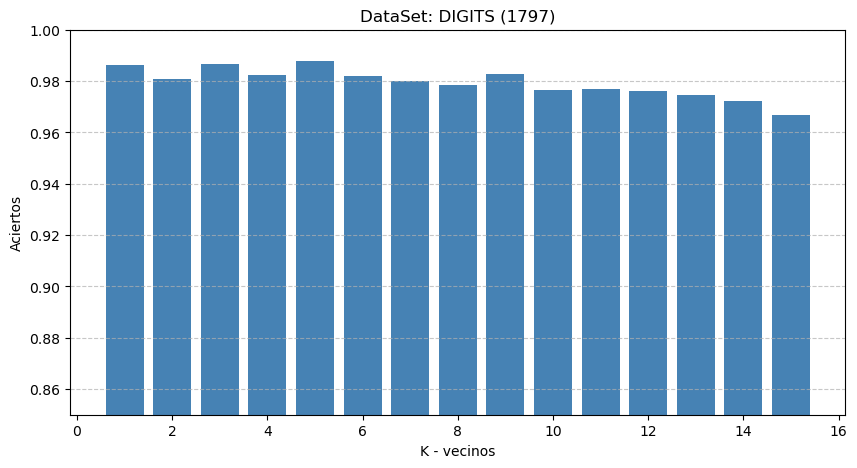

In [22]:
#Hacer diagrama de barras

plt.figure(figsize=(10, 5))
plt.bar(k_valores, aciertos_medios, color='steelblue')
plt.xlabel('K - vecinos')
plt.ylabel('Aciertos')
plt.title('DataSet: DIGITS (1797)')
plt.ylim(0.85, 1.0)
plt.xticks(range(0, 17, 2))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# ----------------------------------- EJERCICIO 2 --------------------------------------------------------

In [41]:
digits = load_digits()
X_original = digits.data
y = digits.target

#Transformar los datos en binario
X_binario_manual = []

# Recorrer las instancias
for instancia in X_original:
    instancia_binaria = [] 
    
    # Si el pixel es mayor que 0, 1 si no 0
    for pixel in instancia:
        if pixel > 0:
            instancia_binaria.append(1) 
        else:
            instancia_binaria.append(0) 
            
   
    X_binario_manual.append(instancia_binaria)

# Usar la nueva x binaria
X_binario = np.array(X_binario_manual)

k_valores = range(1, 16)
aciertos_medios_binario = []

In [42]:
for k in tqdm(k_valores, desc="Evaluando K-vecinos en Binario"):
    aciertos_iteracion = []
    
    
    for _ in range(10):

        
        X_train, X_test, y_train, y_test = train_test_split(X_binario, y, test_size=1/3)
        
      
        knn = KNeighborsClassifier(n_neighbors=k, algorithm='brute')
        knn.fit(X_train, y_train)
        
        
        y_pred = knn.predict(X_test)
        aciertos_iteracion.append(accuracy_score(y_test, y_pred))
        

    
    aciertos_medios_binario.append(np.mean(aciertos_iteracion))

Evaluando K-vecinos en Binario: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:02<00:00,  5.83it/s]


In [43]:
k_optimo = k_valores[np.argmax(aciertos_medios_binario)]
tasa_optima = max(aciertos_medios_binario)

In [44]:
k_optimo

6

In [45]:
tasa_optima

np.float64(0.9046744574290484)

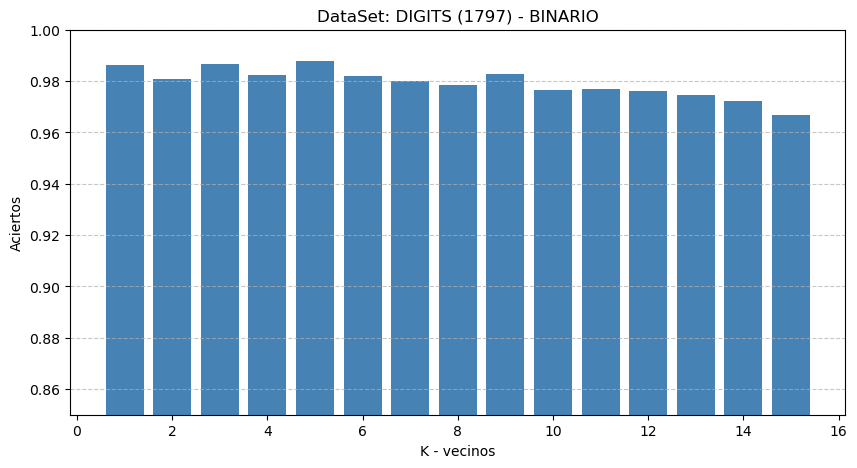

In [46]:
plt.figure(figsize=(10, 5))
plt.bar(k_valores, aciertos_medios, color='steelblue')
plt.xlabel('K - vecinos')
plt.ylabel('Aciertos')
plt.title('DataSet: DIGITS (1797) - BINARIO')
plt.ylim(0.85, 1.0)
plt.xticks(range(0, 17, 2))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()